In [3]:
%load_ext autoreload
%autoreload 2
%pylab inline

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [4]:
import sys
sys.path.append("../..")

In [5]:
from rom_tools.rom_manager import RomManager

In [6]:
rom_m = RomManager("../../../roms/sm_guinea_pig.smc", "../../../roms/sm_newlevel.smc")

In [7]:
from rom_tools import graphics

In [8]:
tileset_table = graphics.get_tileset_table(rom_m)
cre_tile_sheet = graphics.get_cre_tilesheet(rom_m)
cre_tile_table = graphics.get_cre_tile_table(rom_m)

In [9]:
objnames = rom_m.parse()

In [10]:
# 7ACB3 - Bubble Mountain
lb = objnames["room_header_0x7acb3"].state_chooser.default.level_data.level_bytes

In [11]:
from world_rando.coord import *

In [12]:
def default(state):
    return state.state_chooser.default

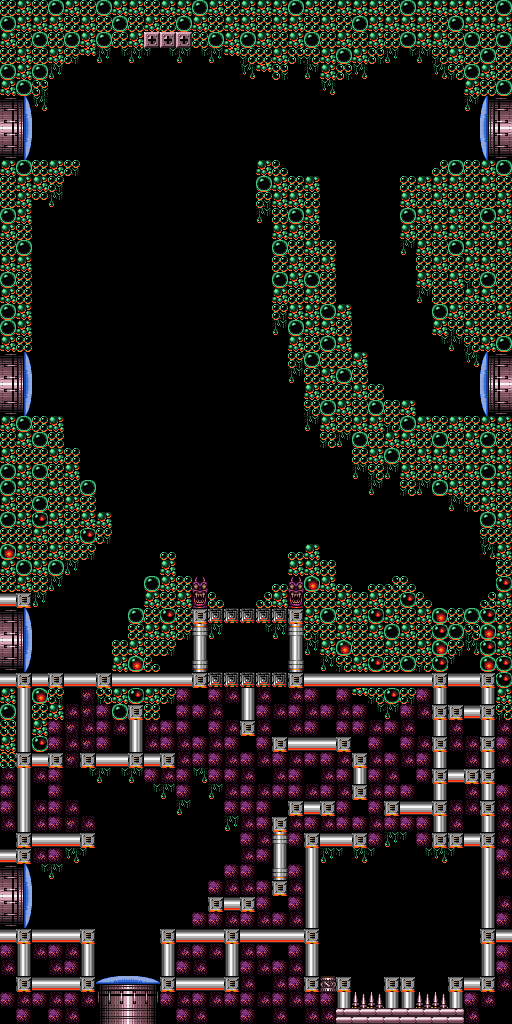

In [13]:
limage = graphics.image_from_state(default(objnames["room_header_0x7acb3"]), rom_m)
# Gross PIL stuff
limage2 = limage.convert("RGB")
limage2

In [14]:
level_array = objnames["room_header_0x7acb3"].state_chooser.default.level_data.level_array.layer1

In [15]:
from world_rando.isovision import *

In [411]:
is_air = mk_is_air(level_array)

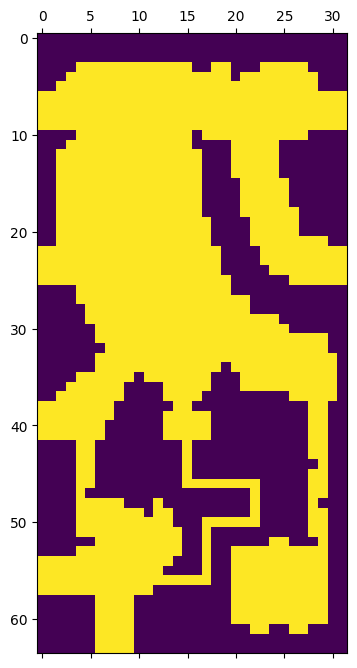

In [412]:
matshow(is_air.T)

In [527]:
# Find the angle (in radians) from the given pivot to the given point (assuming the x-axis is 0 radians)
def point_angle(pivot, point):
    # Determine the quadrant of the point
    x_offset = point.x - pivot.x
    y_offset = point.y - pivot.y
    x_nneg = x_offset > 0
    y_nneg = y_offset > 0
    # Special case for identical points
    if pivot == point:
        assert False, "Angle calculation impossible for overlapping points!"
    # Special case for points with the same x-coord
    if point.x == pivot.x:
        if y_nneg:
            return math.pi / 2
        else:
            return 3 * math.pi / 2
    # Special case for points with the same y-coord
    if point.y == pivot.y:
        if x_nneg:
            return 0
        else:
            return math.pi
    # Q1
    if x_nneg and y_nneg:
        #print("Q1")
        return math.atan(y_offset / x_offset)
    # Q2
    elif (not x_nneg) and y_nneg:
        #print("Q2")
        return math.pi / 2 + math.atan(-x_offset / y_offset)
    # Q3
    elif (not x_nneg) and (not y_nneg):
        #print("Q3")
        return math.pi + math.atan(-y_offset / -x_offset) # this is the same as Q1
    # Q4
    elif x_nneg and (not y_nneg):
        #print("Q4")
        return 3 * math.pi / 2 + math.atan(x_offset / -y_offset) # this is the same as Q2
    else:
        assert False, "Angle cases not exhaustive!"

In [19]:
# In actual fact, all of these calculations will probably be upside-down because in SM, the +Y axis is down the screen!

In [20]:
twopi = 2 * math.pi

In [21]:
from itertools import combinations
from functools import reduce

In [22]:
from abc import ABC, abstractmethod

In [23]:
# Angles are in [0, 2*pi) with angle 2*pi aliasing to 0
def angle_inbounds(angle):
    return angle >= 0 and angle < twopi

class AngleSetInterface(ABC):

    @abstractmethod
    def has(self, angle):
        pass

    @abstractmethod
    def overlaps(self, other):
        pass

    @abstractmethod
    def __or__(self, other):
        pass

    @abstractmethod
    def __and__(self, other):
        pass

    @abstractmethod
    def __sub__(self, other):
        pass

    @abstractmethod
    def copy(self):
        pass

    @abstractmethod
    def size(self):
        pass

def all_interval():
    i = Interval(0,0)
    i.special = True
    return i

def none_interval():
    return AngleSet([])

# Represents angle intervals
# start is an angle in [0, 2*pi)
# end is an angle in [0, 2*pi)
# (An interval of width zero means the object cannot be seen, or can only be seen by a single ray)

# Attempt to make an interval, but if the interval is singleton, make an empty set instead
# Useful for intersections that overlap on the boundaries
def mk_nonsingle_interval(start, end):
    if start == end:
        return AngleSet([])
    return Interval(start, end)

#TODO: what if a singleton set is attempted to be created? (e.g. by intersecting two intervals that share one point?)
class Interval(AngleSetInterface):

    pure = True
    
    def __init__(self, start, end):
        assert angle_inbounds(start)
        assert angle_inbounds(end)
        self.start = start
        self.end = end
        # An interval where start == end and special == False represents a single visible point
        # This is commonly the case when viewing the end of a segment, for example
        #assert start != end, "NoneInterval created!"
        # start > end iff the interval crosses 0 radians and wraps back around
        self.special = self.start > self.end
        if self.special:
            # The true end is an angle >= 2*pi
            self.width = self.end + twopi - self.start
        else:
            self.width = self.end - self.start
        assert angle_inbounds(self.width)

    # Checks if this interval contains the given angle (inclusive)
    def has(self, angle):
        assert angle_inbounds(angle)
        if self.special:
            # The angle is between twopi and the actual start
            if angle >= self.start:
                return True
            # angle is between 0 and aliased end
            elif angle <= self.end:
                return True
            else:
                return False
        else:
            return angle >= self.start and angle <= self.end

    def overlaps(self, other):
        if not other.pure:
            promote = AngleSet([self])
            return promote.overlaps(other)
        return (self.has(other.start) or self.has(other.end)) or (other.has(self.start) or other.has(self.start))

    # Returns true iff self wraps around other so that the clockwise order is:
    # other.start, self.end, self.start, other.end
    def wraps_around(self, other):
        #TODO: this is also true iff self.has(other.start) or self.has(other.end) (unless the two sets are coterminous...)
        if other.has(self.start) and other.has(self.end):
            # Special case for singleton sets, which never wrap around
            if self.start == self.end and not self.special:
                return False
            i = Interval(other.start, self.start)
            return i.has(self.end)
        else:
            return False

    # Union
    def __or__(self, other):
        if not other.pure:
            promote = AngleSet([self])
            return promote | other
        # If the endpoints of the other interval are inside of self, then 
        if self.has(other.start) and self.has(other.end):
            # One of two cases:
            # 1. other is contained within self: SS OS OE SE (clockwise)
            # 2. other wraps around self: SS OE OS SE (clockwise)
            if other.wraps_around(self):
                return all_interval() #TODO: this is problematic if we allow other.start = other.end to represent singleton sets
            else:
                return self.copy()
        elif self.has(other.start):
            return Interval(self.start, other.end)
        elif self.has(other.end):
            return Interval(other.start, self.end)
        # If other.has(self.start) but !other.has(self.end) then self.has(other.end), so this case is already covered
        elif other.has(self.start) and other.has(self.end):
            if self.wraps_around(other):
                return all_interval()
            else:
                return self.copy()
        # If they are not overlapping, make an angleset that includes both
        else:
            return AngleSet([self.copy(), other.copy()])            

    # Intersection
    def __and__(self, other):
        if not other.pure:
            promote = AngleSet([self])
            return promote & other
        if self.has(other.start) and self.has(other.end):
            # This is analagous to the union operation
            # other splits self into two parts if it wraps around
            if other.wraps_around(self):
                # This happens if other is an AllInterval
                if other.end == other.start:
                    return self.copy()
                # This happens iff self is an AllInterval
                elif self.end == self.start:
                    return other.copy()
                else:
                    return AngleSet([mk_nonsingle_interval(self.start, other.end), mk_nonsingle_interval(other.start, self.end)])
            else:
                return other.copy()
        elif self.has(other.start):
            return mk_nonsingle_interval(other.start, self.end)
        elif self.has(other.end):
            return mk_nonsingle_interval(self.start, other.end)
        elif other.has(self.start) and other.has(self.end):
            # self wraps around
            if self.wraps_around(other):
                if self.end == self.start:
                    return other.copy()
                elif other.end == other.start:
                    return self.copy()
                else:
                    return AngleSet([mk_nonsingle_interval(other.start, self.end), mk_nonsingle_interval(self.start, other.end)])
            else:
                return self.copy()
        # If they are not overlapping, the intersection is empty
        else:
            return none_interval()

    # Setminus
    def __sub__(self, other):
        if not other.pure:
            promote = AngleSet([self])
            return promote - other
        if self.has(other.start) and self.has(other.end):
            # If it wraps around, then only the area between the wrap around is preserved
            if other.wraps_around(self):
                if other.end == other.start:
                    return none_interval()
                else:
                    #TODO: this nonsingle is redunant with the previous check
                    return mk_nonsingle_interval(other.end, other.start)
            # If it doesn't wrap around, then it splits self into two regions
            else:
                return AngleSet([Interval(self.start, other.start), Interval(other.end, self.end)])
        elif self.has(other.start):
            return mk_nonsingle_interval(self.start, other.start)
        elif self.has(other.end):
            return mk_nonsingle_interval(other.end, self.end)
        #TODO: sub is not symmetric, so check this!
        elif other.has(self.start) and other.has(self.end):
            # If other is an allinterval then everything is removed
            if other.start == other.end:
                return none_interval()
            elif self.wraps_around(other):
                return mk_nonsingle_interval(other.end, other.start)
            # If self does not wrap around, then it is contained within other and everything is removed
            else:
                return none_interval()
        # If they are not overlapping, nothing is removed
        else:
            return self.copy()

    def copy(self):
        return Interval(self.start, self.end)

    def size(self):
        s = self.end - self.start
        if self.special:
            return s + twopi
        else:
            return s

    def __repr__(self):
        return f"Interval({self.start}, {self.end})"

#TODO: Rename to IntervalSet?
#TODO: possible performance improvement:
# Require angles to be ordered by clockwise start so that we can determine quickly where they interact
# Represents a set of angles as zero or more non-overlappng intervals
class AngleSet(AngleSetInterface):

    pure = False

    def __init__(self, intervals):
        self.intervals = []
        for i in intervals:
            self.add_interval(i)
        assert len(self.check_overlap()) == 0

    def has(self, angle):
        return any([i.has(angle) for i in self.intervals])

    def overlaps_interval(self, interval):
        return any([i.overlaps(interval) for i in self.intervals])

    # Check all n^2 interval pairs for overlap
    def overlaps(self, other):
        return any([self.overlaps_interval(i) for i in other.intervals])

    def check_overlap(self):
        overlaps = []
        for i,j in combinations(self.intervals, 2):
            if i.overlaps(j):
                overlaps.append((i,j))
        return overlaps

    #TODO: the way this is implemented means it takes n^2 time to build an AngleSet with n angles
    def add_interval(self, add_i):
        assert add_i.pure, add_i
        overlaps = []
        non_overlaps = []
        for i in self.intervals:
            # If the intervals overlap then adding the interval alters the interval
            if i.overlaps(add_i):
                overlaps.append(i)
            else:
                non_overlaps.append(i)
        base = add_i
        # The intervals are non-overlapping:
        # Any interval that does not overlap with add also does not overlap with add | o forall o
        for o in overlaps:
            base |= o
            assert base.pure
        self.intervals = non_overlaps + [base]

    def intersect_interval(self, int_i):
        assert int_i.pure, int_i
        overlaps = []
        for i in self.intervals:
            if i.overlaps(int_i):
                overlaps.append(i)
        #print("Overlaps: ", overlaps)
        # Intersection of the union is the union of the intersections
        # Intersections are mutually disjoint because they are smaller than the original (disjoint) sets
        new_intervals = []
        for o in overlaps:
            new_i = o & int_i
            if new_i.pure:
                new_intervals.append(new_i)
            else:
                new_intervals.extend(new_i.intervals)
        self.intervals = new_intervals

    def subtract_interval(self, sub_i):
        assert sub_i.pure, sub_i
        overlaps = []
        non_overlaps = []
        for i in self.intervals:
            if i.overlaps(sub_i):
                overlaps.append(i)
            else:
                non_overlaps.append(i)
        new_intervals = []
        for o in overlaps:
            new_i = o - sub_i
            if new_i.pure:
                new_intervals.append(new_i)
            else:
                new_intervals.extend(new_i.intervals)
        self.intervals = non_overlaps + new_intervals

    # Union
    #TODO what if "self" is not pure?
    def __or__(self, other):
        ss = self.copy()
        if other.pure:
            ss.add_interval(other)
            return ss
        for i in other.intervals:
            ss.add_interval(i)
        return ss

    # Intersection
    def __and__(self, other):
        if other.pure:
            ss = self.copy()
            ss.intersect_interval(other)
            return ss
        # Intersection of the union is the union of the intersection
        #TODO: it seems extremely inefficient to copy self so many times...
        base = AngleSet([])
        for i in other.intervals:
            ss = self.copy()
            ss.intersect_interval(i)
            base = base | ss
        return base

    # Removes other from self, creating a new AngleSet
    def __sub__(self, other):
        ss = self.copy()
        if other.pure:
            ss.subtract_interval(other)
            return ss
        for i in other.intervals:
            ss.subtract_interval(i)
        return ss

    def size(self):
        size = 0
        for i in self.intervals:
            size += i.size()
        assert size <= twopi
        return size

    def copy(self):
        return AngleSet([i.copy() for i in self.intervals])

    def __repr__(self):
        return f"AngleSet({self.intervals.__repr__()})"

In [24]:
epsilon = 10**-10

In [25]:
# The corners of a coord
def coord_points(c):
    return [Coord(c.x, c.y), Coord(c.x + 1, c.y), Coord(c.x, c.y + 1), Coord(c.x + 1, c.y + 1)]

def coord_center(c):
    return Coord(c.x + 0.5, c.y + 0.5)

# Returns true iff point lies on the line that passes through both a and b
def point_on_line(point, line):
    a, b = line
    if a == b:
        assert False, "does not define a line!"
    return (b.x - a.x) * (point.y - a.y) == (point.x - a.x) * (b.y - a.y)

# Returns true iff point lies on the segment from a to b
def point_on_segment(point, segment):
    a, b = line
    # Point must be within the bounding box of the line segment
    minx = min(a.x, b.x)
    maxx = max(a.x, b.x)
    if point.x < minx or point.x > maxx:
        return False
    miny = min(a.y, b.y)
    maxy = max(a.y, b.y)
    if point.y < miny or point.y > maxy:
        return False
    return point_on_line(point, a, b)

# returns False if the point does not lie on the segment
# Otherwise, returns the t-value (progress along the segment)
def point_on_segment_t(point, line):
    # First, solve for t
    a, b = line
    # Line is defined by a + (b-a)*t
    # so a + (b-a)*t = p is a system of two equations
    # t = (p - a) / (b - a)
    if a.x != b.x:
        t = (point.x - a.x) / (b.x - a.x)
    elif a.y != b.y:
        t = (point.y - a.y) / (b.y - a.y)
    # This happens if a == b
    else:
        assert False, "does not define a line!"
    if t < 0 or t > 1:
        return False
    else:
        return t

def line_intersect(line1, line2):
    # line 1 = a1 + (a2 - a1) * t
    a1, a2 = line1
    # line 2 = b1 + (b2 - b1) * t
    b1, b2 = line2
    mat = np.array([
        [a2.x - a1.x, b1.x - b2.x], 
        [a2.y - a1.y, b1.y - b2.y]])
    #print(mat)
    # Solve a1 + (a2 - a1) * t1 = b1 + (b2 - b1) * t2 for t1, t2
    try:
        mat_inv = np.linalg.inv(mat)
        #print(mat_inv)
    # If the matrix is singular, then the lines are parallel
    except LinAlgError:
        # They could be on top of each other
        if point_on_line(a1, line2):
            return a1, None, True
        # Otherwise, these are parallel lines that do not intersect
        else:
            return None
    #print(b1 - a1)
    t = mat_inv @ (b1 - a1)
    #print(t)
    eq1 = a1 + (a2 - a1).scale(t[0])
    eq2 = b1 + (b2 - b1).scale(t[1])
    #assert eq1 == eq2, (eq1, eq2)
    assert abs(eq1.x - eq2.x) < epsilon, (eq1, eq2)
    assert abs(eq1.y - eq2.y) < epsilon, (eq1, eq2)
    return eq1, t, False

def line_segment_intersect(line1, line2):
    s = line_intersect(line1, line2)
    if s is None:
        return None
    else:
        p, t, same_line = s
        # If the lines are the same then they intersect iff (WLOG) one of the endpoints of a lies within b
        if same_line:
            a1, a2 = line1
            if point_on_line(a1, line2):
                return a1 # Among other points
            elif point_on_line(a2, line2):
                return a2
            # The lines are the same but the segments don't overlap
            else:
                return None
        # If the lines are not parallel, then they intersect at p
        else:
            # The segments intersect iff p is inside both of them
            if t[0] >= 0 and t[0] <= 1 and t[1] >= 0 and t[1] <= 1:
                return p
            else:
                return None

def line_segment_touches_xplus(segment):
    a, b = segment
    # It only crosses if one is above and the other is below
    if (a.y >= 0 and b.y <= 0) or (a.y <= 0 and b.y >= 0):
        # The line segment is coterminous with the x axis
        if a.y == b.y:
            return True
        # The line crosses the x-axis somewhere
        # Solve the y part of parametric equation [x, 0] = [b.x - a.x, b.y - a.y] * t + [a.x, a.y] for t:
        t = a.y / (a.y - b.y)
        # Substitute t back into the x part
        x = b.x * t - a.x * t + a.x
        # The line crosses at (x, 0)
        if x >= 0:
            return True
        else:
            return False
    else:
        return False

# OUTMODED because of the ambiguous case when a line starts on the x axis.
# However, still potentially useful for the case of an arbitrary line and not a segment
# If the line segment crosses the X+ axis, then the larger of the two angles is the clockwise start of the segment
# and the segment wraps around 0 radians
#if line_segment_touches_xplus((rel_a, rel_b)):

#TODO: if the pivot lies on the line defined by (a,b), then the interval occupied by the line is empty (or only contains one point?)
#TODO: what if a=b?
def line_segment_interval(pivot, line):
    point_a, point_b = line
    angle_a = point_angle(pivot, point_a)
    angle_b = point_angle(pivot, point_b)
    min_angle = min(angle_a, angle_b)
    max_angle = max(angle_a, angle_b)
    if (max_angle - min_angle) >= math.pi:
        i = Interval(max_angle, min_angle)
    else:
        i = Interval(min_angle, max_angle)
    # A line segment cannot take up half the field of view
    assert i.size() < math.pi
    return i

# Find the vision angles that the visible surface of the given coordinate occupies when standing at the center of the pivot coord
# Any angle strictly within (start, end) will hit the square at c unless it hits something else first
#TODO: what about the endpoints?
def angle_interval(pivot, c):
    if pivot == c:
        assert False, "The angle interval for overlapping points is undefined!"
    center = coord_center(pivot)
    ps = coord_points(c)
    angles = [point_angle(center, p) for p in ps]
    #TODO this is wrong for intervals that straddle the x axis!
    start = min(angles)
    end = max(angles)
    return (start, end)

def angle_intersect(viewpoint, angle, segment):
    ray = (viewpoint, Coord(viewpoint.x + math.cos(angle), viewpoint.y + math.sin(angle)))
    i = line_intersect(ray, segment)
    #print(i)
    if i is None:
        return None
    else:
        p, t, same_line = i
        # If it actually hits the segment, return the intersection point
        if t[1] >= -epsilon or t[1] <= 1 + epsilon:
            return p
        else:
            return None

In [26]:
def segment_fraction(line, fraction):
    a,b = line
    rel_b = b - a
    return a + rel_b.scale(fraction)

In [76]:
# Returns true iff viewpoint is on the same side of line as point
# This is the same as saying that point is visible from viewpoint with respect to line
def point_infront(viewpoint, point, line):
    #TODO: what if viewpoint = point?
    #TODO: what if viewpoint is on line?
    #TODO: what if point is on line?
    ray = (viewpoint, point)
    i = line_intersect(ray, line)
    # Happens if viewpoint -> point is parallel to line. Unless viewpoint lies on line, point will always be on the same side as viewpoint
    if i is None:
        #print("Parallel View Ray")
        return True
    else:
        _, t, same_line = i
        if same_line:
            #print("Same View Ray")
            return True
        else:
            #print("Ray Intersects")
            #print(t, t[0] <= 0)
            #if t[0] <= 0 or t[0] >= 1
            if t[0] <= epsilon or t[0] >= 1-epsilon:
                return True
            else:
                return False

# Determine what part of line1 is visible from point if line2 is also present
def occlude(point, line1, line2):
    a1, a2 = line1
    b1, b2 = line2
    a1_infront = point_infront(point, a1, line2)
    #print(a1, a1_infront)
    a2_infront = point_infront(point, a2, line2)
    #print(a2, a2_infront)
    # If both a points are in front, then line1 is in front of line2, and no occlusion happens
    if a1_infront and a2_infront:
        #print("Both in front (Case 1)")
        return line_segment_interval(point, line1)
    # If both points are behind, then line2 occludes line1
    elif not a1_infront and not a2_infront:
        #print("Both behind (Case 2)")
        return line_segment_interval(point, line1) - line_segment_interval(point, line2)
    # If one is behind and the other is in front, then the lines line1 and line2 must intersect at some point p (though the segments may not intersect).
    # If we call the infront point I and the behind J, then [I, p] is always visible and [p, J] may be occluded by line2
    # The visible part of line1 is [I, p] u ([p, J] - line2)
    elif not a1_infront and a2_infront:
        infront = a2
        behind = a1
    elif a1_infront and not a2_infront:
        infront = a1
        behind = a2
    #print("One in front (Case 3)")
    intersect = line_intersect(line1, line2)
    #print(line1, line2)
    #print(intersect)
    assert len(intersect) == 3
    p, _, _ = intersect
    s1 = line_segment_interval(point, (infront, p))
    s2 = line_segment_interval(point, (p, behind))
    return s1 | (s2 - line_segment_interval(point, line2))


In [540]:
ii = line_segment_interval(Coord(0,0), (Coord(1,1), Coord(1,-1)))
ii = line_segment_interval(Coord(0,0), (Coord(-1,1), Coord(-1,-1)))

In [541]:
ii.start, ii.end, ii.size == twopi / 4

(2.356194490192345, 3.9269908169872414, True)

In [544]:
l0 = (Coord(0,0), Coord(4,0))
l1 = (Coord(1,1), Coord(1,-1))
l2 = (Coord(0.5, 2), Coord(0.5, 0))
o = occlude(Coord(0,0), l1, l2)
#i1 = line_segment_interval(Coord(0,0), (Coord(1,1), Coord(1,-1)))
#i2 = line_segment_interval(Coord(0,0), (Coord(0.5, 2), Coord(0.5, 0)))
o.size == twopi / 8

True

In [545]:
line_intersect(l0, l1)

(c(1.0,0.0), array([0.25, 0.5 ]), False)

In [500]:
# Find the boundaries for each direction (some cells may have multiple boundaries)
def mk_boundaries(is_air, include_bounds=True):
    boundaries = {}
    for d in cardinal_ds:
        boundaries[d] = set()
        for c in iter2d(is_air):
            if inbounds(c + d, is_air) and is_air[c] == -1 and is_air[c + d] == 1:
                boundaries[d].add(c)
            if include_bounds and is_air[c] == 1 and not inbounds(c + d, is_air):
                boundaries[d].add(c)
    return boundaries

#TODO: consider a smoothing algorithm that makes non-axis-aligned surfaces (e.g. marching squares)

def mk_boundary_surfaces(is_air):
    surfaces = []
    surfaces.append((Coord(0, 0), Coord(0, is_air.shape[1])))
    surfaces.append((Coord(0, 0), Coord(is_air.shape[0], 0)))
    surfaces.append((Coord(is_air.shape[0], 0), Coord(is_air.shape[0], is_air.shape[1])))
    surfaces.append((Coord(0, is_air.shape[1]), Coord(is_air.shape[0], is_air.shape[1])))
    return surfaces

def mk_lines(is_air):
    surfaces = []
    # subsegs[a] = [b], the subsegments that make up the segment a
    subsegs = {}
    boundaries = mk_boundaries(is_air, True)
    ortho = {up: right, down: right, left: down, right: down}
    add = {up: Coord(0,0), down: Coord(0,1), left: Coord(0,0), right: Coord(1,0)}
    # Find maximal surfaces
    for c in iter2d(is_air):
        for d in cardinal_ds:
            o = ortho[d]
            if c in boundaries[d]:
                #print(c)
                these_subsegs = []
                extend = c
                while inbounds(extend, is_air) and extend in boundaries[d]:
                    boundaries[d].remove(extend)
                    extend = extend + o
                    seg = (extend + add[d], extend + add[d] + o)
                    these_subsegs.append(seg)
                segment = (c + add[d], extend + add[d])
                surfaces.append(segment)
                subsegs[segment] = these_subsegs
    # Add surfaces that cover the boundaries
    #surfaces.extend(mk_boundary_surfaces(is_air))
    return surfaces, subsegs

def mk_tiles(is_air):
    surfaces = []
    boundaries = mk_boundaries(is_air)
    ortho = {up: right, down: right, left: down, right: down}
    add = {up: Coord(0,0), down: Coord(0,1), left: Coord(0,0), right: Coord(1,0)}
    for d in boundaries:
        for t in boundaries[d]:
            segment = (t + add[d], t + add[d] + ortho[d])
            surfaces.append(segment)
    return surfaces

In [548]:
from world_rando.room_perception.perceptual_flux import *

In [550]:
surfaces, subsegs = mk_lines(is_air)
#surfaces = mk_tiles(is_air)

In [551]:
len(surfaces)

202

In [552]:
from matplotlib import collections as mc

In [553]:
surfaces[0:1]

[(c(0,6), c(2,6))]

In [554]:
offset = Coord(-0.5, -0.5)

def drawc(coord):
    c2 = coord + offset
    scatter(c2.x, c2.y)

def draw_segs(segments, color="royalblue", offset = offset):
    surfaces = [(s + offset, t + offset) for (s,t) in segments]
    lc = mc.LineCollection(surfaces, linewidths = 2, color=color)
    ax = gca()
    ax.add_collection(lc)

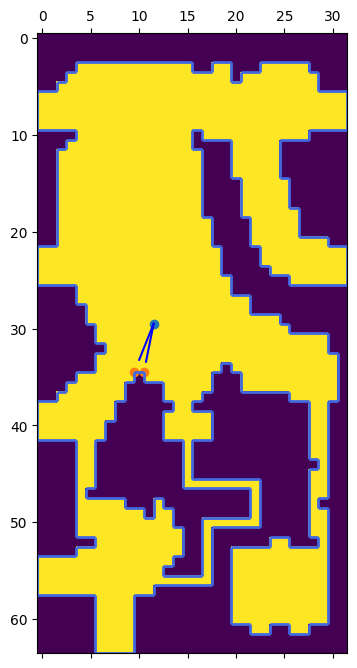

In [555]:
# Draw the surfaces
# MPL draws the matrix squares centered at the coordinate

#matshow(is_air[:10,:10].T)
matshow(is_air.T)
draw_segs(surfaces)
#scatter(range(5),range(5))
#scatter(30-.5, 12-.5)
scatter(12-.5, 30-.5)
#scatter(12, 30)
#scatter(13, 30)
scatter([10-.5, 11-.5], [35-.5, 35-.5])
t1 = 1.9513027039072615
t2 = 1.7681918866447774
plot([12-.5, 12-.5 + 4 * math.cos(t2)], [30-.5, 30-.5 + 4 * math.sin(t2)], color="blue")
plot([12-.5, 12-.5 + 4 * math.cos(t1)], [30-.5, 30-.5 + 4 * math.sin(t1)], color="blue")
#scatter(25, 55)

In [454]:
def mk_perception(point, surfaces):
    ordered_surfaces = sorted(surfaces, key=lambda x: segment_fraction(x, 0.5).euclidean(point))
    #]print(len(ordered_surfaces))
    fully_occluded = set()
    perception = {}
    # Generate initial perceptions (without occlusion)
    for surface in ordered_surfaces:
        perception[surface] = line_segment_interval(point, surface)
    # Occlude the surfaces
    for surface in ordered_surfaces:
        # Occluded surfaces do not need to be processed since any surface which is (partially) occluded by a fully occluded surfaces is
        # at least as occluded by the surfaces that occlude the surface which would occlude it (yes)
        if surface in fully_occluded:
            continue
        for surface2 in ordered_surfaces:
            if surface2 in fully_occluded:
                continue
            # Surface may occlude surface2
            #print(surface, surface2)
            visible = occlude(point, surface2, surface)
            #print(perception[surface2], visible)
            perception[surface2] = perception[surface2] & visible
            assert perception[surface2] is not None
            if perception[surface2].size() == 0:
                fully_occluded.add(surface2)
                pass
    return perception, fully_occluded

In [483]:
test_point = Coord(12, 30)
#test_point = Coord(25, 55)
perception, fully_occluded = mk_perception(test_point, surfaces)

In [484]:
len(fully_occluded)

146

In [485]:
perception_clean = {k:v for k,v in perception.items() if v.size() > 0}

In [486]:
len(perception_clean), len(perception)

(56, 202)

In [487]:
from matplotlib.tri import Triangulation

In [488]:
def interval_points(point, segment, interval):
    p1 = angle_intersect(point, interval.start, segment)
    p2 = angle_intersect(point, interval.end, segment)
    # The endpoints of the visible part of a segment should be on the segment
    assert p1 is not None
    assert p2 is not None
    return (p1, p2)

def set_points(point, segment, set):
    if set.pure:
        return [interval_points(point, segment, set)]
    else:
        return [interval_points(point, segment, i) for i in set.intervals]

def triangularize(point, perception):
    points = [point]
    triangles = []
    for k,v in perception.items():
        #print(v)
        sp = set_points(point, k, v)
        #print(sp, len(sp))
        for pair in sp:
            #print("pair:", pair)
            p1, p2 = pair
            i1 = len(points)
            points.append(p1)
            i2 = i1 + 1
            points.append(p2)
            # Will this be anticlockwise??
            #print(p1, p2)
            triangles.append((0, i1, i2))
    x = np.array([p.x for p in points])
    y = np.array([p.y for p in points])
    t = np.array(triangles)
    return x, y, t

In [489]:
xs, ys, ts = triangularize(test_point, perception_clean)

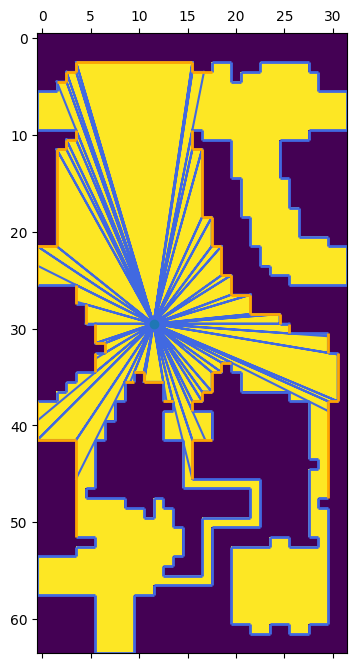

In [490]:
matshow(is_air.T)
xs_plot = xs - 0.5
ys_plot = ys - 0.5
triangles = Triangulation(xs_plot, ys_plot, ts)
triplot(triangles, color="royalblue")
#scatter(xs_plot, ys_plot)

drawc(test_point)

foxs = []
foys = []
for seg in fully_occluded:
    foxs.append(seg[0].x)
    foxs.append(seg[1].x)
    foys.append(seg[0].y)
    foys.append(seg[1].y)
fo_surfaces = [(a + offset, b + offset) for a,b in fully_occluded]
#scatter(np.array(foxs) -.5, np.array(foys) -.5)
draw_segs(fully_occluded)
draw_segs(perception_clean.keys(), "orange")

#seg_start = Coord(16, 4)
#seg_end = Coord(18, 4)
#seg = (seg_start, seg_end)
#seg_b = (Coord(16, 10), Coord(16, 12))
#seg_c = (Coord(16, 12), Coord(17, 12))
#draw_segs([seg, seg_b, seg_c], color="lime")

#seg2_start = Coord(16, 42)
#seg2_end = Coord(18, 42)
#seg2 = (seg2_start, seg2_end)
#draw_segs([seg2], color="lime")

# Fixed
#seg_start = Coord(31, 33)
#seg_end = Coord(31, 38)
#seg = (seg_start, seg_end)
#draw_segs([seg], color="lime")

#seg3_start = Coord(26, 31)
#seg3_end = Coord(30, 31)
#seg3_b = (Coord(26, 30), Coord(26, 31))
#seg3_c = (Coord(25, 29), Coord(25, 30))
#seg3 = (seg3_start, seg3_end)
#draw_segs([seg3, seg3_b, seg3_c], color="lime")


In [491]:
#perception_clean
#seg_a = (Coord(24, 24), Coord(24, 25))
#seg_b = (Coord(20, 25), Coord(20, 27))
#int_a = perception_clean[seg_a]
#int_b = perception_clean[seg_b]
perception[seg]

AngleSet([])

In [526]:
def mk_perception_good(point, perception, subsegments):
    good_perception = {}
    for surface, visible_set in perception.items():
        for sub in subsegments[surface]:
            good_perception[sub] = line_segment_interval(point, sub) & visible_set
    return good_perception

def mk_surface_probs(perception):
    return {k: (v.size() / twopi) for k,v in perception.items()}

def surface_entropy(probs):
    entropy = 0
    for k,v in probs.items():
        if v != 0:
            entropy -= v * math.log(v, 2)
    return entropy

def prob_add(prob, prob_add, weight=1):
    for k,v in prob_add.items():
        if k in prob:
            prob[k] = prob[k] + (v * weight)
        else:
            prob[k] = (v * weight)

def mk_mixture(probs, weights=None):
    mixture = {}
    if weights is None:
        weights = [1] * len(probs)
    for i, p in enumerate(probs):
        prob_add(mixture, p, weights[i])
    return {k : v / sum(weights) for k,v in mixture.items()}

# JSD assuming the variable X is "which surface was hit by the ray"
def surface_prob_jsd(prob_a, prob_b):
    mixture = mk_mixture([prob_a, prob_b])
    h_m = surface_entropy(mixture)
    h_a = surface_entropy(prob_a)
    h_b = surface_entropy(prob_b)
    return h_m - 0.5 * (h_a + h_b)

def perception_surface_distance(perception_a, perception_b):
    prob_a = mk_surface_probs(perception_a)
    prob_b = mk_surface_probs(perception_b)
    return surface_prob_jsd(prob_a, prob_b)

In [85]:
test2 = Coord(12, 31)
perception2, _ = mk_perception(test2, surfaces)

In [86]:
sum(list(surface_probs(perception2).values()))

1.0

In [87]:
perception_surface_distance(perception, perception2)

0.010315337390740531

In [96]:
from tqdm.notebook import tqdm

In [524]:
def mk_all_surface_probs(is_air, surfaces, subsegments, good=True):
    surface_probs = {}
    for c in tqdm(iter2d(is_air)):
        if is_air[c] == 1:
            cc = c + Coord(0.5, 0.5)
            p, _ = mk_perception(cc, surfaces)
            if good:
                surface_probs[c] = mk_surface_probs(mk_perception_good(cc, p, subsegments))
            else:
                surface_probs[c] = mk_surface_probs(p)
    return surface_probs

In [525]:
surface_probs = mk_all_surface_probs(is_air, surfaces, subsegs)

0it [00:00, ?it/s]

In [353]:
def mk_neighbor_infos(is_air, surface_probs):
    infos = np.zeros_like(is_air)
    for c in iter2d(infos):
        if is_air[c] == 1:
            p_a = surface_probs[c]
            jsds = []
            for d in cardinal_ds:
                #c2 = c + (d.scale(2))
                c2 = c + d
                if inbounds(c2, is_air) and is_air[c2] == 1:
                    p_b = surface_probs[c2]
                    jsds.append(surface_prob_jsd(p_a, p_b))
            if len(jsds) > 0:
                infos[c] = sum(jsds) / len(jsds)
                #infos[c] = max(jsds)
    return infos

In [ ]:
infos = mk_neighbor_infos(is_air, surface_probs)

In [241]:
def mk_distance(is_air):
    distance = np.zeros_like(is_air)
    for c in iter2d(is_air):
        if is_air[c] == -1:
            distance[c] = 0
        else:
            distance[c] = -1
    changed = True
    while changed:
        distance_k = np.zeros_like(is_air)
        changed = False
        for c in iter2d(is_air):
            m = None
            if distance[c] == -1:
                for d in cardinal_ds:
                    c2 = c + d
                    if inbounds(c2, is_air) and distance[c2] != -1:
                        if m is None:
                            m = distance[c2] + 1
                        else:
                            m = min(m, distance[c2] + 1)
                if m is not None:
                    changed = True
                    distance_k[c] = m + 1 # +1 to cancel the -1
        distance = distance + distance_k
    return distance

In [242]:
tile_dists = mk_distance(is_air)

In [249]:
#matshow(tile_dists.T)

In [396]:
#TODO: scale based on distance
#TODO: integral estimation
#TODO: smoothed surfaces
#TODO: another pdf distance metric?
#TODO: more that two points in the divergence?
#TODO: penalty for merging larger regions?
#TODO: Local minima
# 
#TODO: Merging regions based on the divergence of their mixtures
#TODO: weighted sum based on the distance to the edge
#TODO: separate wall cap segments
#TODO: treat quicksand as air
#TODO: make slope tiles have sloped segments
#TODO: max size for surfaces

In [333]:
def mk_minima(infos, is_air):
    minima = []
    for c in iter2d(infos):
        if is_air[c] == 1:
            is_min = True
            for d in cardinal_ds:
                c2 = c + d
                if inbounds(c2, infos) and is_air[c2] == 1 and infos[c2] < infos[c]:
                    is_min = False
            if is_min:
                minima.append(c)
    return minima

In [334]:
minima = mk_minima(infos, is_air)

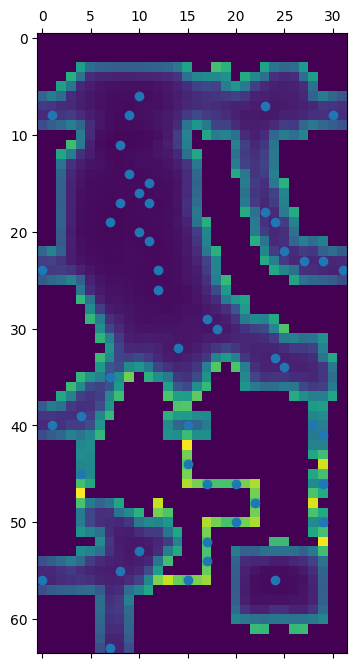

In [335]:
matshow(infos.T)
scatter([c.x for c in minima], [c.y + 0. for c in minima])

In [284]:
from heapdict import heapdict

In [328]:
def agglomerate(minima, surface_probs, threshold):
    cluster_mixes = {frozenset([c]): surface_probs[c] for c in minima}
    cluster_ds = heapdict({})
    for (c1, c2) in combinations(minima, 2):
        c1s = frozenset([c1])
        c2s = frozenset([c2])
        cluster_ds[(c1s, c2s)] = surface_prob_jsd(cluster_mixes[c1s], cluster_mixes[c2s])
    (c1, c2), min_d = cluster_ds.popitem()
    n = 0
    while min_d < threshold and len(cluster_ds) > 0:
        merge = c1 | c2
        merge_mix = mk_mixture([cluster_mixes[c1], cluster_mixes[c2]], [len(c1), len(c2)])
        del cluster_mixes[c1]
        del cluster_mixes[c2]
        for c in cluster_mixes:
            cluster_ds[(c, merge)] = surface_prob_jsd(cluster_mixes[c], merge_mix)
        cluster_mixes[merge] = merge_mix
        #print(n)
        n+=1
        while True:
            (c1, c2), min_d = cluster_ds.popitem()
            if c1 in cluster_mixes and c2 in cluster_mixes:
                break
    return cluster_mixes

In [337]:
glom = agglomerate(minima, surface_probs, 0.6)

In [342]:
def draw_cluster(glom):
    for cluster in glom:
        xs = [c.x for c in cluster]
        ys = [c.y for c in cluster]
        scatter(xs, ys)
        ac = Coord(sum(xs) / len(xs), sum(ys) / len(ys))
        segs = [(ac, c) for c in cluster]
        draw_segs(segs, offset = Coord(0,0))

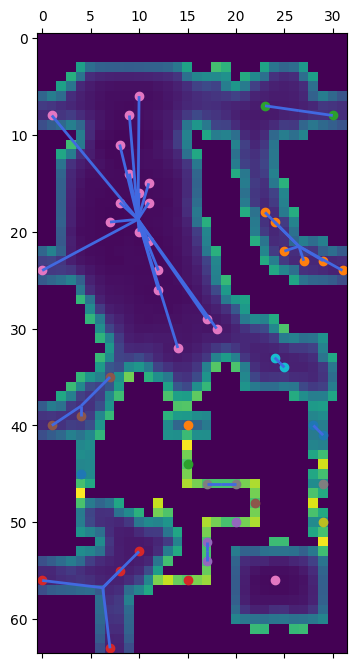

In [343]:
matshow(infos.T)
draw_cluster(glom)

In [432]:
bad_surfaces = mk_lines(is_air)

In [433]:
points = set([])
for (c1, c2) in bad_surfaces:
    points.add(c1)
    points.add(c2)

In [434]:
def tri_coord(tri, index):
    return Coord(tri.x[index], tri.y[index])

def tri_voronoi(tri):
    centers = []
    for t in tri.triangles:
        c1, c2, c3 = [tri_coord(tri, k) for k in t]
        center = (c1 + c2 + c3).scale(1/3)
        centers.append(center)
    return centers

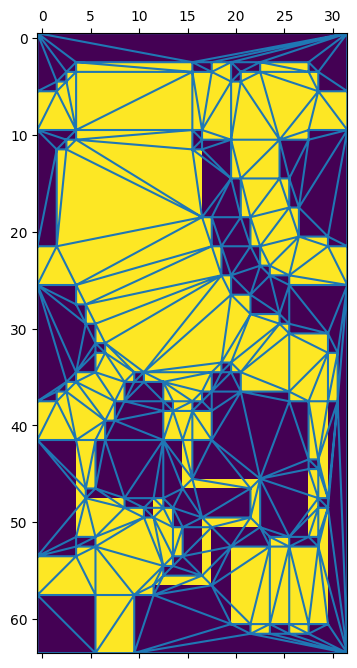

In [435]:
xs = np.array([c.x for c in points])
ys = np.array([c.y for c in points])
xs_plot = xs - 0.5
ys_plot = ys - 0.5
tri = Triangulation(xs_plot, ys_plot)
centers = tri_voronoi(tri)
cxs = [c.x for c in centers]
cys = [c.y for c in centers]
matshow(is_air.T)
triplot(tri)
#scatter(cxs, cys)

In [425]:

#tri.triangles.shape
#tri.neighbors
#tri.x
for t in tri.triangles:
    x,y,z = t

In [122]:
# 79E52 - Green_Hill_Zone
ghz_state = objnames["room_header_0x79e52"].state_chooser.default
ghz_array = objnames["room_header_0x79e52"].state_chooser.default.level_data.level_array.layer1

In [123]:
ghz_is_air = mk_is_air(ghz_array)

In [127]:
ghz_surfaces = mk_lines(ghz_is_air)

In [131]:
ghz_surface_probs = {}
for c in tqdm(iter2d(ghz_is_air)):
    if ghz_is_air[c] == 1:
        p, _ = mk_perception(c + Coord(0.5, 0.5), ghz_surfaces)
        ghz_surface_probs[c] = mk_surface_probs(p)

0it [00:00, ?it/s]

In [143]:
ghz_infos = np.zeros_like(ghz_is_air)
for c in iter2d(ghz_infos):
    if ghz_is_air[c] == 1:
        p_a = ghz_surface_probs[c]
        jsds = []
        for d in cardinal_ds:
            #c2 = c + (d.scale(2))
            c2 = c + d
            if inbounds(c2, ghz_is_air) and ghz_is_air[c2] == 1:
                p_b = ghz_surface_probs[c2]
                jsds.append(surface_prob_jsd(p_a, p_b))
        if len(jsds) > 0:
            #infos[c] = sum(jsds) / len(jsds)
            ghz_infos[c] = max(jsds)

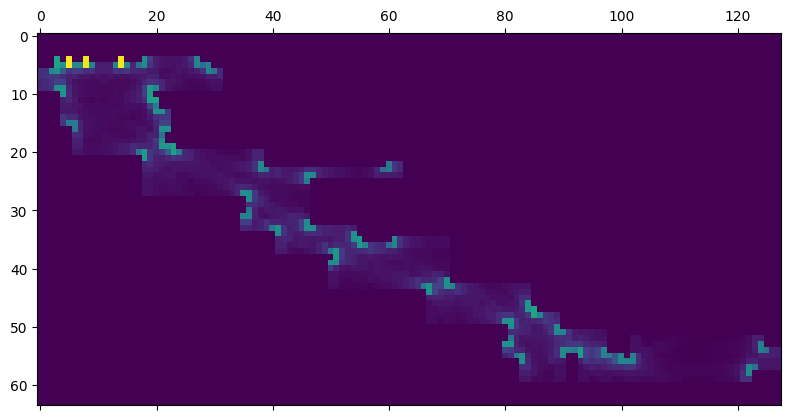

In [144]:
matshow(ghz_infos.T)

In [344]:
ghz_minima = mk_minima(ghz_infos, ghz_is_air)

In [350]:
glom = agglomerate(ghz_minima, ghz_surface_probs, 0.6)

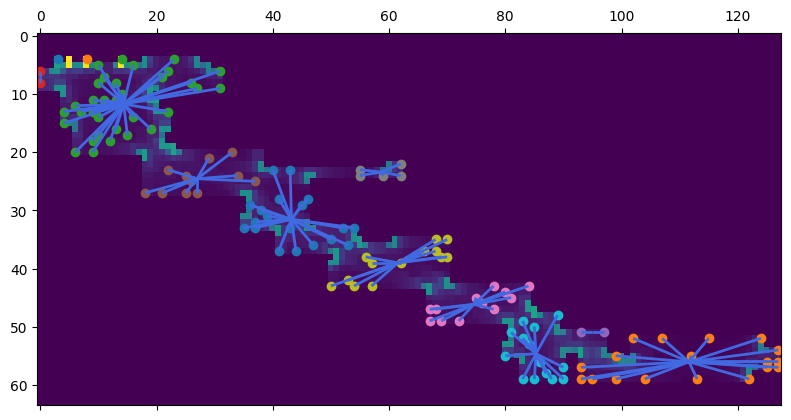

In [351]:
matshow(ghz_infos.T)
draw_cluster(glom)

In [400]:
def compute_surfaces(room_name, objnames):
    room_state = objnames[room_name].state_chooser.default
    room_array = objnames[room_name].state_chooser.default.level_data.level_array.layer1
    is_air = mk_is_air(room_array)
    #surfaces = mk_lines(is_air)
    surfaces = mk_tiles(is_air)
    surface_probs = mk_all_surface_probs(is_air, surfaces)
    infos = mk_neighbor_infos(is_air, surface_probs)
    return is_air, surface_probs, infos

def show_clusters(is_air, surface_probs, infos):
    minima = mk_minima(infos, is_air)
    glom = agglomerate(minima, surface_probs, 0.535)
    matshow(infos.T)
    draw_cluster(glom)
    return glom

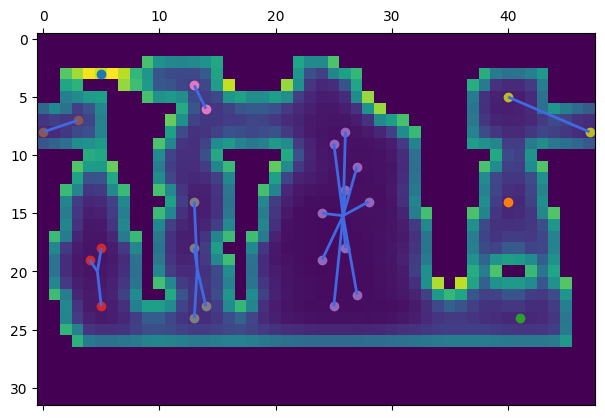

In [402]:
_ = show_clusters(*surface_stuff)

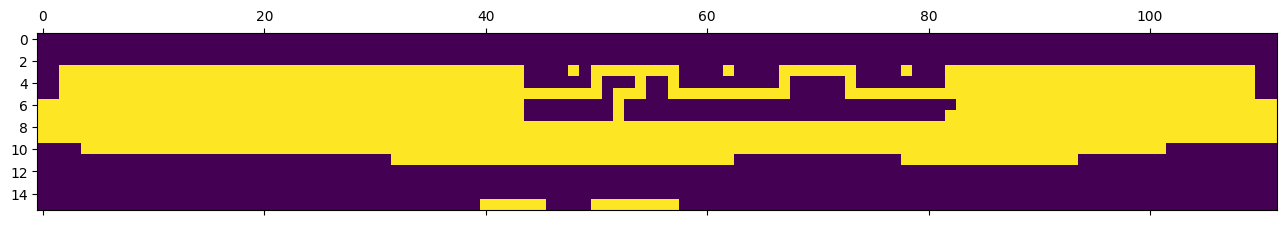

In [374]:
matshow(is_air.T)

In [167]:
class NoneInterval(AngleSetInterface):
    
    delegate = True
    singleton = True
    all = False
    none = True

    def __init__(self):
        return

    def has(self, angle):
        return False

    def overlaps(self, other):
        return False

    def __or__(self, other):
        return other.copy()

    def __and__(self, other):
        return NoneInterval()

    def __sub__(self, other):
        return NoneInterval()

    # Computes other - self
    def reverse_minus(self, other):
        return other.copy()

    def copy(self):
        return NoneInterval()

class AllInterval(AngleSetInterface):
    
    delegate = True
    singleton = True
    all = True
    none = False

    def __init__(self):
        return

    def has(self, angle):
        return True

    def overlaps(self, other):
        if other.none:
            return False
        else:
            return True

    def __or__(self, other):
        return AllInterval()

    def __and__(self, other):
        return other.copy()

    def __sub__(self, other):
        # this is problematic for AngleSets and NoneIntervals
        return Interval(other.end, other.start)

    # Computes other - self
    def reverse_minus(self, other):
        return NoneInterval()

    def copy(self):
        return AllInterval()

In [ ]:
def mk_perceptions(airs, solids):
    # Maps "air" coords to perceptions
    # Each perception is a dict that maps (a subset of) solids to intervals
    perception_table = collections.defaultdict(dict)
    # The occlusion map maps "air" coords to a set of solids that are *fully* occluded by other solids at that air coord
    # Occluded solids can be ignored (they have 0 interval and do not occlude other tiles since occlusion is transitive)
    occlusion = {}
    for air in airs:
        occlusion[air] = set()
        # First, compute the interval for each tile:
        for solid in solids:
            perception_table[air][solid] = angle_interval(air, solid)
        # Now, occlude!
        for solid1 in solids:
            # Ignore fully-occluded tiles
            if solid1 in occlusion[air]:
                continue
            # any other solid square may be (partially) occluded by the visible part of solid1
            for solid2 in solids:
                if solid2 == solid:
                    continue
                # if solid1 is wider than solid2 then solid1 may occlude solid2
                # if the opposite is the case (solid2 may occlude solid1) then we'll get to that later
